# Notebook 13C — Diagnose the retraining reliability result

**Question:** Why does the updated Policy B XGBoost predict much more risk on 2023 Freddie Mac loans than the frozen model?

Notebook 13B showed that retraining did not improve the four reliability metrics. Here we examine the **score distributions**, **where Brier error comes from**, and **calibration across meaningful risk groups**. We also look at descriptive patterns across several origination-time characteristics.

This is an **exploratory diagnostic**, not a new training experiment or a causal explanation. We do **not** refit, recalibrate, adjust thresholds, tune hyperparameters, or replace either model. We only load the saved models and score the same 2023 loans. No loan-level predictions or identifiers are exported.

## 1. Verify the original data and saved models

The first two code cells use the same verification and evaluation procedure as Notebook 13B. We reuse its validated 2023 loan population and confirm the frozen model reproduces Notebook 11. The 13B aggregate results are checked again before doing new diagnostics.

In [1]:
from pathlib import Path
import sys, json, hashlib, zipfile
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from IPython.display import display

ROOT = (Path.cwd().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd()).resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.freddie_features import (REQUIRED_SOURCE_COLUMNS, PREDICTOR_COLUMNS,
    NUMERIC_FEATURES, build_engineered_features, apply_preprocessing_contract)

DATA = ROOT / 'data' / 'processed' / 'Freddie_Mac'
BASE = DATA / 'model_baselines_2015_2017'
RUN_ID = '20261111T161902005765Z'  # Reviewed Stage 2 run; change only if the saved run differs
UPDATE_DIR = DATA / 'notebook_13_updated_xgboost' / RUN_ID
REFERENCE_DIR = DATA / 'notebook_13_retraining_evaluation' / RUN_ID
OUTPUT_DIR = DATA / 'notebook_13_retraining_diagnostics' / RUN_ID

MODEL_DATA = DATA / 'freddie_modeling_dataset_2015_2023_24m.parquet'
BASE_MANIFEST = BASE / 'model_manifest.json'
FEATURE_CONTRACT = BASE / 'freddie_feature_contract.json'
UPDATE_MANIFEST = UPDATE_DIR / 'updated_model_manifest.json'
SAVED_PREDICTIONS = BASE / 'oot_evaluation' / 'oot_predictions_2018_2023.parquet'
SAVED_BINS = BASE / 'oot_evaluation' / 'frozen_calibration_bins.json'
KEYS = ['SOURCE YEAR', 'LOAN IDENTIFIER']
TARGET = 'TARGET_COMPOSITE_CREDIT_EVENT'

def require(ok, message):
    if not ok:
        raise ValueError(message)

def sha256(path):
    with Path(path).open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()

for p in [MODEL_DATA, BASE_MANIFEST, FEATURE_CONTRACT, UPDATE_MANIFEST,
          SAVED_PREDICTIONS, SAVED_BINS]:
    require(p.is_file(), f'Missing required file: {p}')

baseline_info = json.loads(BASE_MANIFEST.read_text(encoding='utf-8'))
update_info = json.loads(UPDATE_MANIFEST.read_text(encoding='utf-8'))
contract = json.loads(FEATURE_CONTRACT.read_text(encoding='utf-8'))
frozen_path = BASE / baseline_info['models']['xgboost']['artifact']
updated_path = UPDATE_DIR / update_info['model_filename']
for p in [frozen_path, updated_path]:
    require(p.is_file(), f'Missing model: {p}')

require(sha256(MODEL_DATA) == baseline_info['input_file_sha256'], 'Modeling data changed.')
require(sha256(FEATURE_CONTRACT) == baseline_info['feature_contract_sha256'], 'Frozen contract changed.')
require(sha256(FEATURE_CONTRACT) == update_info['original_feature_contract_sha256'],
        'Stage 2 used a different feature contract.')
require(sha256(frozen_path) == baseline_info['models']['xgboost']['sha256'] == update_info['frozen_model_sha256'],
        'Frozen model has changed.')
require(sha256(updated_path) == update_info['updated_model_sha256'], 'Updated model has changed.')
require(baseline_info['predictors'] == PREDICTOR_COLUMNS and len(PREDICTOR_COLUMNS) == 29,
        'The 29-predictor definition differs.')
require(contract['training_years'] == [2015, 2016, 2017], 'Contract training years differ.')
require(update_info['primary_training_policy'] == 'B_full_window_individual'
        and update_info['decision_month'] == '2023-01', 'The Stage 2 policy differs.')
require(update_info['sample_rows'] == 285070 and update_info['sample_events'] == 5179,
        'Training sample counts do not match the reviewed results.')
require(update_info['original_fitted_preprocessing_reused'] is True,
        'Stage 2 did not confirm frozen preprocessing reuse.')
require(update_info['evaluation_cohorts'] == ['2023-H1', '2023-H2'],
        'Evaluation cohort list differs.')

frozen_model = joblib.load(frozen_path)
updated_model = joblib.load(updated_path)

# Compare all configured XGBoost settings, treating NaN missing-value defaults as equal.
# A direct dictionary == test may falsely report a change because NaN != NaN.
def equal_setting(a, b):
    if a is None or b is None:
        return a is b
    if isinstance(a, (float, np.floating)) and isinstance(b, (float, np.floating)):
        if np.isnan(a) and np.isnan(b):
            return True
    if isinstance(a, np.ndarray) or isinstance(b, np.ndarray):
        return bool(np.array_equal(a, b, equal_nan=True))
    return bool(a == b)

frozen_params = frozen_model.named_steps['model'].get_params()
updated_params = updated_model.named_steps['model'].get_params()
all_keys = sorted(set(frozen_params) | set(updated_params))
mismatches = [key for key in all_keys
              if key not in frozen_params or key not in updated_params
              or not equal_setting(frozen_params[key], updated_params[key])]
if mismatches:
    print('XGBoost settings requiring review:')
    for key in mismatches:
        print(f'  {key}: frozen={frozen_params.get(key)!r}, updated={updated_params.get(key)!r}')
require(not mismatches, 'XGBoost settings actually differ; review the listed settings before continuing.')
for key, value in baseline_info['models']['xgboost']['selected_params'].items():
    require(equal_setting(frozen_params.get(key), value) and
            equal_setting(updated_params.get(key), value),
            f'Selected baseline setting changed: {key}')
require(update_info['all_original_xgboost_parameters_preserved'] is True,
        'Stage 2 did not confirm original XGBoost parameter preservation.')
print('All XGBoost settings match (including NaN-safe missing-value handling).')
np.testing.assert_array_equal(
    frozen_model.named_steps['prepare'].get_feature_names_out(),
    updated_model.named_steps['prepare'].get_feature_names_out()
)
print('Model and data fingerprints verified.')
print('Primary training policy:', update_info['primary_training_policy'])
print('Training loans:', update_info['sample_rows'], '| positive events:', update_info['sample_events'])

All XGBoost settings match (including NaN-safe missing-value handling).
Model and data fingerprints verified.
Primary training policy: B_full_window_individual
Training loans: 285070 | positive events: 5179


In [2]:
raw = pd.read_parquet(MODEL_DATA, columns=list(dict.fromkeys([*REQUIRED_SOURCE_COLUMNS, 'HORIZON_MONTHS'])))
raw['SOURCE YEAR'] = pd.to_numeric(raw['SOURCE YEAR'], errors='raise').astype(int)
raw['LOAN IDENTIFIER'] = raw['LOAN IDENTIFIER'].astype('string')
require(len(raw) == 437668 and not raw.duplicated(KEYS).any(), 'Validated modeling data totals differ.')
raw_2023 = raw.loc[raw['SOURCE YEAR'].eq(2023)].copy()
require(raw_2023['HORIZON_MONTHS'].eq(24).all(), 'Unexpected label horizon.')
del raw

engineered = build_engineered_features(raw_2023)
prepared = apply_preprocessing_contract(engineered, contract)
require(not prepared[PREDICTOR_COLUMNS].isna().any().any(), 'Missing model predictors.')
require(np.isfinite(prepared[NUMERIC_FEATURES].to_numpy(dtype=float)).all(),
        'Infinite or missing numeric predictor.')
X = prepared.loc[:, PREDICTOR_COLUMNS]
evaluation = prepared.loc[:, KEYS + ['ORIGINATION QUARTER', TARGET]].copy()
q = pd.to_numeric(evaluation['ORIGINATION QUARTER'].astype('string').str.strip().str.removeprefix('Q'),
                  errors='raise').astype(int)
require(q.isin([1, 2, 3, 4]).all(), 'Invalid quarter value.')
evaluation['period'] = np.where(q.le(2), '2023-H1', '2023-H2')
evaluation = evaluation.rename(columns={TARGET: 'y_true'}).drop(columns='ORIGINATION QUARTER')
require(not evaluation.duplicated(KEYS).any(), 'Duplicate evaluation keys.')
evaluation['p_frozen'] = frozen_model.predict_proba(X)[:, 1]
evaluation['p_updated'] = updated_model.predict_proba(X)[:, 1]

saved = pd.read_parquet(SAVED_PREDICTIONS)
require(set(KEYS + ['y_true', 'p_xgboost', 'half_year']).issubset(saved.columns),
        'Saved Notebook 11 prediction columns differ.')
saved['SOURCE YEAR'] = pd.to_numeric(saved['SOURCE YEAR'], errors='raise').astype(int)
saved['LOAN IDENTIFIER'] = saved['LOAN IDENTIFIER'].astype('string')
saved = saved.loc[saved['SOURCE YEAR'].eq(2023),
                  KEYS + ['y_true', 'p_xgboost', 'half_year']].copy()
require(not saved.duplicated(KEYS).any(), 'Duplicate saved prediction keys.')
joined = evaluation.merge(saved, how='outer', on=KEYS, validate='one_to_one',
                          indicator=True, suffixes=('', '_saved'))
require(joined['_merge'].eq('both').all(), '2023 loan keys do not match saved Notebook 11 predictions.')
require(joined['y_true'].eq(joined['y_true_saved']).all() and
        joined['period'].eq(joined['half_year']).all(),
        '2023 outcomes or cohort names differ from Notebook 11.')
np.testing.assert_allclose(joined['p_frozen'], joined['p_xgboost'], rtol=1e-6, atol=1e-8,
                           err_msg='Frozen XGBoost scores do not reproduce Notebook 11.')
evaluation = joined[KEYS + ['period', 'y_true', 'p_frozen', 'p_updated']].copy()
evaluation = evaluation.sort_values(KEYS).reset_index(drop=True)
for col in ['p_frozen', 'p_updated']:
    require(np.isfinite(evaluation[col]).all() and evaluation[col].between(0, 1).all(),
            f'Invalid probabilities: {col}')

cohort_summary = evaluation.groupby('period', sort=True).agg(
    loans=('y_true', 'size'), events=('y_true', 'sum')).reset_index()
expected = {'2023-H1': (24757, 460), '2023-H2': (24744, 416)}
require(set(cohort_summary['period']) == set(expected), 'Unexpected evaluation cohorts.')
for row in cohort_summary.itertuples(index=False):
    require((row.loans, row.events) == expected[row.period], f'Unexpected counts for {row.period}.')
require(len(evaluation) == 49501 and int(evaluation['y_true'].sum()) == 876,
        'Combined 2023 population differs.')
display(cohort_summary)
print('Total evaluation loans:', len(evaluation), '| positive events:', int(evaluation['y_true'].sum()))
print('Frozen model reproduced Notebook 11 predictions on the same 2023 loans.')

,period,loans,events
0,2023-H1,24757,460
1,2023-H2,24744,416


Total evaluation loans: 49501 | positive events: 876
Frozen model reproduced Notebook 11 predictions on the same 2023 loans.


## 2. Confirm that Notebook 13B metrics reproduce

Before looking at subgroups, verify that the 2023 predictions produce the same ROC-AUC, Average Precision, Brier Score, and risk gap as Notebook 13B. If anything differs, this notebook stops.

In [3]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

REFERENCE_METRICS = REFERENCE_DIR / 'frozen_updated_metrics.csv'
REFERENCE_MANIFEST = REFERENCE_DIR / 'evaluation_manifest.json'
for file in [REFERENCE_METRICS, REFERENCE_MANIFEST]:
    require(file.is_file(), f'Notebook 13B result missing: {file}')

reference_manifest = json.loads(REFERENCE_MANIFEST.read_text(encoding='utf-8'))
require(reference_manifest['evaluation_loans'] == 49501 and reference_manifest['evaluation_events'] == 876,
        '13B evaluation population differs.')
require(reference_manifest['frozen_model_sha256'] == sha256(frozen_path)
        and reference_manifest['updated_model_sha256'] == sha256(updated_path),
        '13B evaluated different model artifacts.')

reference = pd.read_csv(REFERENCE_METRICS)
groups = {
    '2023-H1': evaluation.loc[evaluation['period'].eq('2023-H1')],
    '2023-H2': evaluation.loc[evaluation['period'].eq('2023-H2')],
    '2023-all': evaluation,
}

check_rows = []
for period, data in groups.items():
    y = data['y_true'].to_numpy(dtype=int)
    for model in ['frozen', 'updated']:
        p = data[f'p_{model}'].to_numpy(dtype=float)
        check_rows.append({
            'period': period, 'model': model,
            'loans': len(data), 'events': int(y.sum()), 'prevalence': float(y.mean()),
            'roc_auc': float(roc_auc_score(y, p)),
            'average_precision': float(average_precision_score(y, p)),
            'brier': float(brier_score_loss(y, p)),
            'risk_gap': float(y.mean()-p.mean()),
            'absolute_risk_gap': float(abs(y.mean()-p.mean())),
            'mean_predicted_risk': float(p.mean()),
        })

reproduced = pd.DataFrame(check_rows).sort_values(['period', 'model']).reset_index(drop=True)
reference = reference.sort_values(['period', 'model']).reset_index(drop=True)
require(reproduced[['period', 'model']].equals(reference[['period', 'model']]),
        '13B cohort/model ordering or coverage differs.')
for name in ['loans', 'events', 'prevalence', 'roc_auc', 'average_precision',
             'brier', 'risk_gap', 'absolute_risk_gap', 'mean_predicted_risk']:
    np.testing.assert_allclose(reproduced[name], reference[name], rtol=1e-8, atol=1e-10,
                               err_msg=f'13B metric differs: {name}')
display(reproduced.round(6))
print('All 2023-H1, 2023-H2 and combined metrics reproduce Notebook 13B.')

,period,model,loans,events,prevalence,roc_auc,average_precision,brier,risk_gap,absolute_risk_gap,mean_predicted_risk
0,2023-H1,frozen,24757,460,0.018581,0.761809,0.058220,0.017976,0.006007,0.006007,0.012573
1,2023-H1,updated,24757,460,0.018581,0.755053,0.052815,0.022856,-0.053579,0.053579,0.072159
2,2023-H2,frozen,24744,416,0.016812,0.811951,0.062825,0.016219,0.005139,0.005139,0.011673
3,2023-H2,updated,24744,416,0.016812,0.800119,0.061160,0.021289,-0.056289,0.056289,0.073101
4,2023-all,frozen,49501,876,0.017697,0.786574,0.059271,0.017097,0.005573,0.005573,0.012123
5,2023-all,updated,49501,876,0.017697,0.776548,0.056100,0.022073,-0.054934,0.054934,0.072630


All 2023-H1, 2023-H2 and combined metrics reproduce Notebook 13B.


## 3. How much did predicted risks shift?

First, compare each model's score distribution. The mean predicted risk can hide very different patterns, so we also report percentiles and the percentage of loans above a few descriptive risk levels. These are **not** proposed decision thresholds.

,period,model,loans,observed_rate,mean_prediction,median_prediction,p90,p95,p99,share_at_least_5pct,share_at_least_10pct,share_at_least_20pct
0,2023-H1,frozen,24757,0.018581,0.012573,0.006053,0.029641,0.043435,0.099535,0.037444,0.009856,0.001414
1,2023-H1,updated,24757,0.018581,0.072159,0.052635,0.154117,0.199386,0.294402,0.520055,0.237791,0.049764
2,2023-H2,frozen,24744,0.016812,0.011673,0.005336,0.027631,0.041353,0.091646,0.034513,0.008366,0.001657
3,2023-H2,updated,24744,0.016812,0.073101,0.052437,0.158282,0.203498,0.312099,0.519035,0.240382,0.053185
4,2023-all,frozen,49501,0.017697,0.012123,0.005705,0.028694,0.042507,0.095181,0.035979,0.009111,0.001535
5,2023-all,updated,49501,0.017697,0.072630,0.052531,0.156528,0.201763,0.304765,0.519545,0.239086,0.051474


,loans,share_updated_prediction_higher,share_updated_prediction_lower,mean_update_minus_frozen,median_update_minus_frozen,p10_update_minus_frozen,p90_update_minus_frozen
0,49501,0.99897,0.00103,0.060507,0.044239,0.01346,0.13067


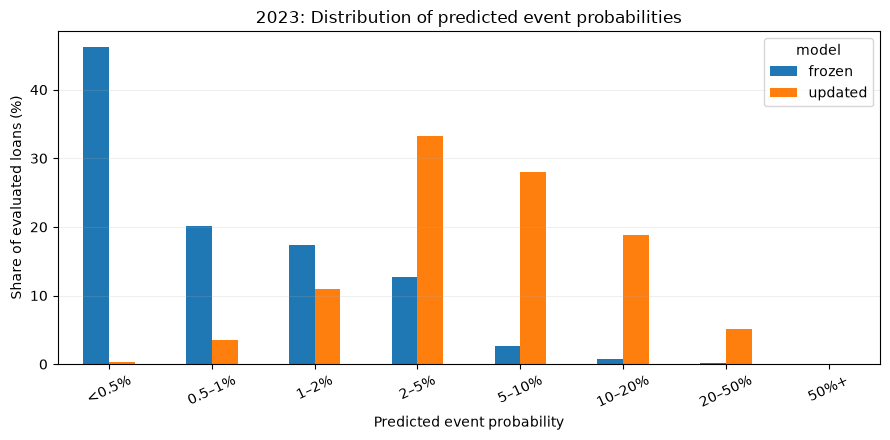

In [4]:
score_rows = []
for period, data in groups.items():
    for model in ['frozen', 'updated']:
        p = data[f'p_{model}'].to_numpy(dtype=float)
        score_rows.append({
            'period': period, 'model': model,
            'loans': len(p), 'observed_rate': float(data['y_true'].mean()),
            'mean_prediction': float(p.mean()),
            'median_prediction': float(np.median(p)),
            'p90': float(np.quantile(p, .90)),
            'p95': float(np.quantile(p, .95)),
            'p99': float(np.quantile(p, .99)),
            'share_at_least_5pct': float((p >= .05).mean()),
            'share_at_least_10pct': float((p >= .10).mean()),
            'share_at_least_20pct': float((p >= .20).mean()),
        })
score_summary = pd.DataFrame(score_rows)

year = groups['2023-all']
change = year['p_updated'].to_numpy() - year['p_frozen'].to_numpy()
score_shift = pd.DataFrame([{
    'loans': len(year),
    'share_updated_prediction_higher': float((change > 0).mean()),
    'share_updated_prediction_lower': float((change < 0).mean()),
    'mean_update_minus_frozen': float(change.mean()),
    'median_update_minus_frozen': float(np.median(change)),
    'p10_update_minus_frozen': float(np.quantile(change, .10)),
    'p90_update_minus_frozen': float(np.quantile(change, .90)),
}])

display(score_summary.round(6))
display(score_shift.round(6))

# Fixed descriptive bands allow both models to be compared on the same probability scale.
score_edges = [0, .005, .01, .02, .05, .10, .20, .50, 1.000001]
score_labels = ['<0.5%', '0.5–1%', '1–2%', '2–5%', '5–10%', '10–20%', '20–50%', '50%+']
band_rows = []
for model in ['frozen', 'updated']:
    band = pd.cut(year[f'p_{model}'], bins=score_edges, labels=score_labels,
                  right=False, include_lowest=True)
    require(band.notna().all(), f'Some {model} probabilities were not assigned to a band.')
    counts = band.value_counts().reindex(score_labels, fill_value=0)
    for label, n in counts.items():
        band_rows.append({'model': model, 'probability_band': label,
                          'loans': int(n), 'share_of_loans': float(n/len(year))})
score_bands = pd.DataFrame(band_rows)
require(score_bands.groupby('model')['loans'].sum().eq(len(year)).all(),
        'Score bands do not cover the entire 2023 population.')

band_plot = score_bands.pivot(index='probability_band', columns='model', values='share_of_loans')
band_plot = band_plot.reindex(score_labels)
fig_bands, ax = plt.subplots(figsize=(9, 4.5))
band_plot.mul(100).plot(kind='bar', ax=ax)
ax.set_title('2023: Distribution of predicted event probabilities')
ax.set_ylabel('Share of evaluated loans (%)')
ax.set_xlabel('Predicted event probability')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.2)
fig_bands.tight_layout()
plt.show()

## 4. Which loans contribute to the Brier Score difference?

Brier Score averages the squared error between predicted probability and the observed 0/1 outcome. We separate the total contribution from **non-events** and **events**. This shows where the extra error appears; it does not prove why the model produced those probabilities.

In [5]:
brier_rows = []
for period, data in groups.items():
    n = len(data)
    y = data['y_true'].to_numpy(dtype=int)
    for model in ['frozen', 'updated']:
        p = data[f'p_{model}'].to_numpy(dtype=float)
        errors = (p-y)**2
        for outcome, label in [(0, 'non_event'), (1, 'event')]:
            is_class = (y == outcome)
            brier_rows.append({
                'period': period, 'model': model, 'outcome': label,
                'loans': int(is_class.sum()),
                'mean_squared_error_within_class': float(errors[is_class].mean()),
                'contribution_to_overall_brier': float(errors[is_class].sum()/n),
            })
brier_detail = pd.DataFrame(brier_rows)
for period, data in groups.items():
    for model in ['frozen', 'updated']:
        part = brier_detail.loc[brier_detail['period'].eq(period) & brier_detail['model'].eq(model)]
        total = part['contribution_to_overall_brier'].sum()
        saved = reproduced.loc[reproduced['period'].eq(period) & reproduced['model'].eq(model), 'brier'].iloc[0]
        np.testing.assert_allclose(total, saved, rtol=1e-10, atol=1e-12)

brier_contrast = brier_detail.pivot_table(
    index=['period', 'outcome'], columns='model', values='contribution_to_overall_brier'
).reset_index()
brier_contrast['updated_minus_frozen'] = brier_contrast['updated']-brier_contrast['frozen']
display(brier_contrast.round(6))
print('Positive updated-minus-frozen contribution means more Brier error after retraining.')

model,period,outcome,frozen,updated,updated_minus_frozen
0,2023-H1,event,0.017464,0.014156,-0.003309
1,2023-H1,non_event,0.000511,0.008700,0.008189
2,2023-H2,event,0.015743,0.012244,-0.003499
3,2023-H2,non_event,0.000475,0.009045,0.008569
4,2023-all,event,0.016604,0.013200,-0.003404
5,2023-all,non_event,0.000493,0.008873,0.008379


Positive updated-minus-frozen contribution means more Brier error after retraining.


## 5. Common risk groups: compare both models on the same loans

Notebook 13B used the frozen development calibration boundaries, but almost all updated predictions ended up in its highest bin. As a supplementary diagnostic, we now divide the **2023 evaluation loans into ten equally sized groups based on the frozen model's score**. The same loans stay together when we compare both predictions with observed events.

These 2023 score deciles are **descriptive and retrospective**. They do not replace the original development-defined monitoring bins and are not used to recalibrate a model.

,frozen_score_decile,loans,events,observed_rate,frozen_mean,updated_mean
0,1,4951,2,0.000404,0.001003,0.015753
1,2,4950,8,0.001616,0.001679,0.027630
2,3,4950,21,0.004242,0.002456,0.035917
3,4,4950,28,0.005657,0.003422,0.044068
4,5,4950,33,0.006667,0.004826,0.056835
5,6,4950,66,0.013333,0.006772,0.070187
6,7,4950,87,0.017576,0.009601,0.082144
7,8,4950,104,0.021010,0.013916,0.097361
8,9,4950,211,0.042626,0.021926,0.123701
9,10,4950,316,0.063838,0.055633,0.172719


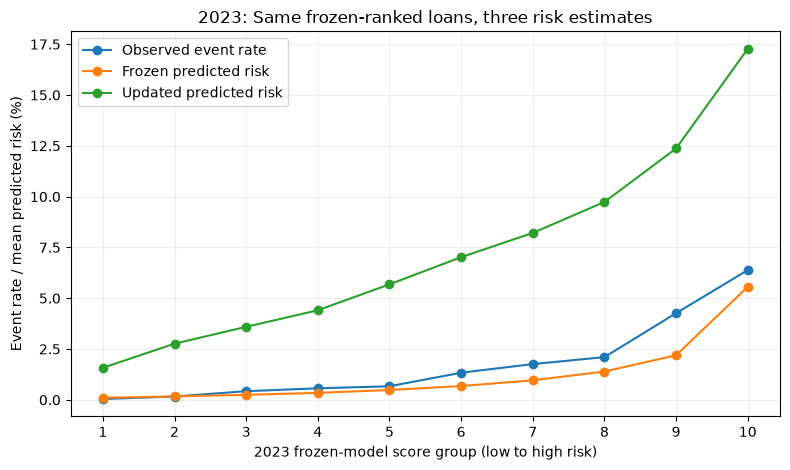

In [6]:
common = evaluation.copy()
common['frozen_score_decile'] = pd.qcut(common['p_frozen'], q=10,
                                           labels=False, duplicates='drop')
require(common['frozen_score_decile'].notna().all(), 'Cannot form frozen-score groups.')
common['frozen_score_decile'] = common['frozen_score_decile'].astype(int)+1
common_calibration = (common.groupby('frozen_score_decile', sort=True)
    .agg(loans=('y_true', 'size'), events=('y_true', 'sum'),
         observed_rate=('y_true', 'mean'),
         frozen_mean=('p_frozen', 'mean'), updated_mean=('p_updated', 'mean'))
    .reset_index())
require(int(common_calibration['loans'].sum()) == len(evaluation), 'Common deciles omit loans.')
display(common_calibration.round(6))

fig_common, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(common_calibration['frozen_score_decile'], common_calibration['observed_rate']*100,
        marker='o', label='Observed event rate')
ax.plot(common_calibration['frozen_score_decile'], common_calibration['frozen_mean']*100,
        marker='o', label='Frozen predicted risk')
ax.plot(common_calibration['frozen_score_decile'], common_calibration['updated_mean']*100,
        marker='o', label='Updated predicted risk')
ax.set_xlabel('2023 frozen-model score group (low to high risk)')
ax.set_ylabel('Event rate / mean predicted risk (%)')
ax.set_title('2023: Same frozen-ranked loans, three risk estimates')
ax.set_xticks(common_calibration['frozen_score_decile'])
ax.grid(alpha=.2)
ax.legend()
fig_common.tight_layout()
plt.show()

## 6. Each model's own 2023 score deciles

For a second view, we form ten groups of roughly equal size **separately for each model**, using its 2023 predictions. This avoids putting nearly all updated scores into one broad historic bin.

**Important:** The frozen and updated deciles do **not** contain the same loans, so their bins should not be treated as paired comparisons. This is a supplementary visualization of each model's calibration shape, not a replacement for the 13B metrics or uncertainty intervals.

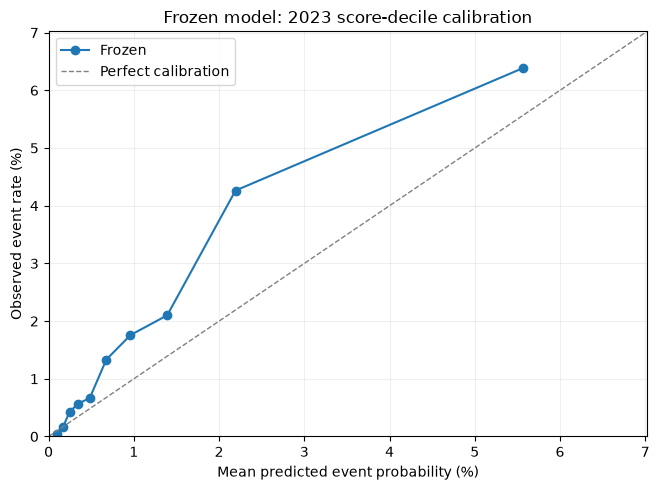

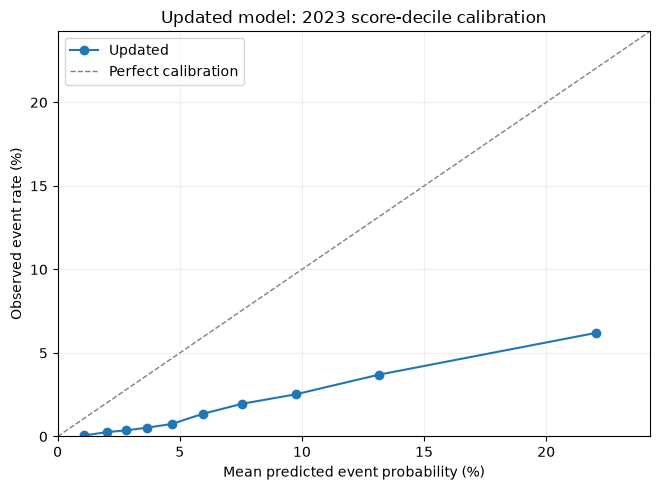

,score_decile,loans,events,observed_rate,mean_prediction,model
0,1,4951,2,0.000404,0.001003,frozen
1,2,4950,8,0.001616,0.001679,frozen
2,3,4950,21,0.004242,0.002456,frozen
3,4,4950,28,0.005657,0.003422,frozen
4,5,4950,33,0.006667,0.004826,frozen
5,6,4950,66,0.013333,0.006772,frozen
6,7,4950,87,0.017576,0.009601,frozen
7,8,4950,104,0.021010,0.013916,frozen
8,9,4950,211,0.042626,0.021926,frozen
9,10,4950,316,0.063838,0.055633,frozen


In [7]:
individual_rows = []
individual_figures = {}
for model in ['frozen', 'updated']:
    temp = evaluation[['y_true', f'p_{model}']].copy()
    temp['score_decile'] = pd.qcut(temp[f'p_{model}'], q=10,
                                   labels=False, duplicates='drop')
    require(temp['score_decile'].notna().all(), f'{model}: score deciles failed.')
    temp['score_decile'] = temp['score_decile'].astype(int) + 1
    deciles = (temp.groupby('score_decile', sort=True)
        .agg(loans=('y_true', 'size'), events=('y_true', 'sum'),
             observed_rate=('y_true', 'mean'),
             mean_prediction=(f'p_{model}', 'mean')).reset_index())
    require(int(deciles['loans'].sum()) == len(evaluation), f'{model}: missing decile loans.')
    deciles['model'] = model
    individual_rows.append(deciles)
    fig, ax = plt.subplots(figsize=(6.7, 5))
    ax.plot(deciles['mean_prediction']*100, deciles['observed_rate']*100,
            'o-', label=model.capitalize())
    upper = 1.1*max(float(deciles['mean_prediction'].max()),
                    float(deciles['observed_rate'].max()), .01)
    ax.plot([0, upper*100], [0, upper*100], '--', linewidth=1,
            color='gray', label='Perfect calibration')
    ax.set_xlim(0, upper*100)
    ax.set_ylim(0, upper*100)
    ax.set_xlabel('Mean predicted event probability (%)')
    ax.set_ylabel('Observed event rate (%)')
    ax.set_title(f'{model.capitalize()} model: 2023 score-decile calibration')
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    individual_figures[model] = fig
    plt.show()

individual_calibration = pd.concat(individual_rows, ignore_index=True)
display(individual_calibration.round(6))

## 7. Explore differences across borrower and loan characteristics

We look at FICO, original interest rate, DTI and LTV. For each characteristic, loans are grouped into quartiles using 2023 values. We compare actual event rates and both models' mean predictions within each group.

These are **associations, not explanations of cause**. The predictors may be correlated with each other and with time. The quartile boundaries are learned from the 2023 evaluation population for description only; they are not fitted preprocessing rules or proposed model changes.

In [8]:
FEATURES_TO_REVIEW = ['FICO_SCORE', 'ORIGINAL_INTEREST_RATE',
                      'ORIGINAL_DTI', 'ORIGINAL_LTV']
additional = prepared[KEYS + FEATURES_TO_REVIEW].copy()
additional['SOURCE YEAR'] = pd.to_numeric(additional['SOURCE YEAR'], errors='raise').astype(int)
additional['LOAN IDENTIFIER'] = additional['LOAN IDENTIFIER'].astype('string')
require(not additional.duplicated(KEYS).any(), 'Duplicate feature keys.')
features_2023 = evaluation.merge(additional, on=KEYS, how='inner', validate='one_to_one')
require(len(features_2023) == len(evaluation), 'Some evaluation features are missing.')

segment_rows = []
for feature in FEATURES_TO_REVIEW:
    quartile = pd.qcut(features_2023[feature], q=4, labels=False, duplicates='drop')
    require(quartile.notna().all(), f'Unable to group {feature} into quantiles.')
    temp = features_2023.copy()
    temp['quartile'] = quartile.astype(int)+1
    for group, part in temp.groupby('quartile', sort=True):
        segment_rows.append({
            'feature': feature, 'quartile': int(group),
            'feature_min': float(part[feature].min()),
            'feature_max': float(part[feature].max()),
            'loans': len(part), 'events': int(part['y_true'].sum()),
            'observed_rate': float(part['y_true'].mean()),
            'frozen_mean': float(part['p_frozen'].mean()),
            'updated_mean': float(part['p_updated'].mean()),
            'frozen_risk_gap': float(part['y_true'].mean()-part['p_frozen'].mean()),
            'updated_risk_gap': float(part['y_true'].mean()-part['p_updated'].mean()),
        })
segment_diagnostics = pd.DataFrame(segment_rows)
for feature in FEATURES_TO_REVIEW:
    require(int(segment_diagnostics.loc[segment_diagnostics['feature'].eq(feature), 'loans'].sum())
            == len(evaluation), f'{feature}: some loans were not covered.')
display(segment_diagnostics.round(5))
print('Descriptive 2023 quartiles only. Do not infer which predictor caused overprediction.')

,feature,quartile,feature_min,feature_max,loans,events,observed_rate,frozen_mean,updated_mean,frozen_risk_gap,updated_risk_gap
0,FICO_SCORE,1,583.000,720.000,12489,546,0.04372,0.02566,0.12192,0.01806,-0.07820
1,FICO_SCORE,2,721.000,758.000,12482,207,0.01658,0.01188,0.08339,0.00470,-0.06680
2,FICO_SCORE,3,759.000,786.000,12527,89,0.00710,0.00611,0.04649,0.00100,-0.03938
3,FICO_SCORE,4,787.000,831.000,12003,34,0.00283,0.00457,0.03744,-0.00174,-0.03461
4,ORIGINAL_INTEREST_RATE,1,2.625,6.250,12701,197,0.01551,0.01089,0.06258,0.00462,-0.04707
5,ORIGINAL_INTEREST_RATE,2,6.259,6.750,13334,203,0.01522,0.01181,0.07313,0.00342,-0.05790
6,ORIGINAL_INTEREST_RATE,3,6.753,7.250,12192,238,0.01952,0.01242,0.07633,0.00711,-0.05681
7,ORIGINAL_INTEREST_RATE,4,7.255,9.125,11274,238,0.02111,0.01357,0.07935,0.00754,-0.05824
8,ORIGINAL_DTI,1,2.000,32.000,12793,109,0.00852,0.00659,0.03788,0.00193,-0.02936
9,ORIGINAL_DTI,2,33.000,40.000,12796,218,0.01704,0.01192,0.05728,0.00511,-0.04024


Descriptive 2023 quartiles only. Do not infer which predictor caused overprediction.


## 8. Save the aggregate review bundle

Save **tables and charts only**, plus the model and input fingerprints. No identifiers, individual predictions, model files or source data go into this ZIP. Do not commit the original data or `.joblib` files to GitHub.

In [9]:
require(sha256(MODEL_DATA) == baseline_info['input_file_sha256'], 'Modeling data changed during analysis.')
require(sha256(frozen_path) == baseline_info['models']['xgboost']['sha256'],
        'Frozen model changed during analysis.')
require(sha256(updated_path) == update_info['updated_model_sha256'],
        'Updated model changed during analysis.')
require(not OUTPUT_DIR.exists(), f'Diagnostic output folder already exists: {OUTPUT_DIR}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

tables = {
    'reference_metrics_check.csv': reproduced,
    'score_distribution_summary.csv': score_summary,
    'paired_score_shift_summary.csv': score_shift,
    'score_probability_bands.csv': score_bands,
    'brier_by_outcome.csv': brier_detail,
    'brier_contribution_difference.csv': brier_contrast,
    'common_frozen_score_deciles.csv': common_calibration,
    'model_specific_score_deciles.csv': individual_calibration,
    'origination_characteristic_quartiles.csv': segment_diagnostics,
}
for name, frame in tables.items():
    frame.to_csv(OUTPUT_DIR / name, index=False)

figures = {
    'score_probability_bands.png': fig_bands,
    'common_frozen_score_deciles.png': fig_common,
    'frozen_own_decile_calibration.png': individual_figures['frozen'],
    'updated_own_decile_calibration.png': individual_figures['updated'],
}
for name, fig in figures.items():
    fig.savefig(OUTPUT_DIR / name, dpi=160, bbox_inches='tight')

review_manifest = {
    'stage': 'Notebook 13C retraining diagnostics',
    'analysis_type': 'retrospective_exploratory_descriptive',
    'stage2_run_id': RUN_ID,
    'stage3b_reference_directory': str(REFERENCE_DIR.relative_to(ROOT)),
    'evaluation_loans': int(len(evaluation)),
    'evaluation_events': int(evaluation['y_true'].sum()),
    'frozen_model_sha256': sha256(frozen_path),
    'updated_model_sha256': sha256(updated_path),
    'modeling_data_sha256': sha256(MODEL_DATA),
    'feature_contract_sha256': sha256(FEATURE_CONTRACT),
    'model_retrained': False,
    'model_recalibrated': False,
    'model_hyperparameters_modified': False,
    'model_threshold_changed': False,
    'evaluation_deciles_used_for_diagnostics_only': True,
    'historical_publication_dates_verified': False,
    'independent_untouched_validation': False,
    'limitations': [
        '2023 subgroup and score-decile comparisons are descriptive and retrospective.',
        'Model-specific deciles do not contain the same loan membership.',
        'Features are correlated; subgroup patterns do not establish causal drivers.',
        'Neither model was recalibrated or updated in this notebook.',
        'Availability dates are proxies and 2023 outcomes were previously examined.',
    ],
}
(OUTPUT_DIR / 'diagnostics_manifest.json').write_text(
    json.dumps(review_manifest, indent=2), encoding='utf-8'
)

review_zip = OUTPUT_DIR / 'notebook_13c_diagnostics_review.zip'
with zipfile.ZipFile(review_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for name in [*tables, *figures, 'diagnostics_manifest.json']:
        archive.write(OUTPUT_DIR / name, arcname=name)
with zipfile.ZipFile(review_zip) as archive:
    require(archive.testzip() is None, 'Review ZIP failed integrity check.')
    require(len(archive.namelist()) == len(tables) + len(figures) + 1,
            'Review ZIP is incomplete.')
print('Notebook 13C diagnostic outputs saved:', OUTPUT_DIR)
print('Share this aggregate review ZIP:', review_zip)
print('Both models and original inputs remain unchanged.')

Notebook 13C diagnostic outputs saved: E:\capstone_project\mortgage-model-reliability\data\processed\Freddie_Mac\notebook_13_retraining_diagnostics\20261111T161902005765Z
Share this aggregate review ZIP: E:\capstone_project\mortgage-model-reliability\data\processed\Freddie_Mac\notebook_13_retraining_diagnostics\20261111T161902005765Z\notebook_13c_diagnostics_review.zip
Both models and original inputs remain unchanged.


## What we will review

We will check whether the overprediction is broad or concentrated in certain scores, whether most Brier deterioration comes from event or non-event loans, and whether it appears across FICO, interest rate, DTI and LTV groups. The new decile charts help describe calibration without changing either model.

**Do not conclude that a particular feature caused the deterioration from these tables alone.** After reviewing the findings, the next planned experiment is **Policy A sensitivity**, followed by a cautious final retraining conclusion.

Save the executed notebook locally and share `notebook_13c_diagnostics_review.zip` first. We will review the results before pushing Notebook 13C to the GitHub feature branch.